Unexpected device failures in a delivery fleet lead to vehicle downtime, delayed shipments and costly emergency repairs. The goal of this project is to build a classification model that predicts device failures from daily telemetry data, so that maintenance can be scheduled *before* a breakdown occurs.

The dataset contains daily readings of 9 anonymized sensor attributes for 1,168 devices over roughly ten months in 2015. Failures are extremely rare (about 0.09% of all records), which makes this a highly imbalanced classification problem. Because a missed failure (false negative) is far more costly to the business than an unnecessary inspection (false positive), the project prioritizes **recall** while keeping false alarms at a manageable level, and uses techniques such as SMOTE and class weighting to handle the imbalance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

pd.set_option('display.float_format', '{:.2f}'.format)

### 1.EDA

In [2]:
df=pd.read_csv('failure.csv')

In [3]:
df.head(5)

,date,device,failure,attribute1,attribute2,attribute3,attribute4,attribute5,attribute6,attribute7,attribute8,attribute9
0,2015-01-01,S1F01085,0,215630672,56,0,52,6,407438,0,0,7
1,2015-01-01,S1F0166B,0,61370680,0,3,0,6,403174,0,0,0
2,2015-01-01,S1F01E6Y,0,173295968,0,0,0,12,237394,0,0,0
3,2015-01-01,S1F01JE0,0,79694024,0,0,0,6,410186,0,0,0
4,2015-01-01,S1F01R2B,0,135970480,0,0,0,15,313173,0,0,3


In [4]:
df.shape

(124494, 12)

In [5]:
df.columns

Index(['date', 'device', 'failure', 'attribute1', 'attribute2', 'attribute3',
       'attribute4', 'attribute5', 'attribute6', 'attribute7', 'attribute8',
       'attribute9'],
      dtype='str')

In [6]:
df.isnull().sum()

date          0
device        0
failure       0
attribute1    0
attribute2    0
attribute3    0
attribute4    0
attribute5    0
attribute6    0
attribute7    0
attribute8    0
attribute9    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

In [9]:
print("Min tarih:", df["date"].min())
print("Max tarih:", df["date"].max())

Min tarih: 2015-01-01 00:00:00
Max tarih: 2015-11-02 00:00:00


In [10]:
df.head(3)

,date,device,failure,attribute1,attribute2,attribute3,attribute4,attribute5,attribute6,attribute7,attribute8,attribute9
0,2015-01-01,S1F01085,0,215630672,56,0,52,6,407438,0,0,7
1,2015-01-01,S1F0166B,0,61370680,0,3,0,6,403174,0,0,0
2,2015-01-01,S1F01E6Y,0,173295968,0,0,0,12,237394,0,0,0


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 124494 entries, 0 to 124493
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        124494 non-null  datetime64[us]
 1   device      124494 non-null  str           
 2   failure     124494 non-null  int64         
 3   attribute1  124494 non-null  int64         
 4   attribute2  124494 non-null  int64         
 5   attribute3  124494 non-null  int64         
 6   attribute4  124494 non-null  int64         
 7   attribute5  124494 non-null  int64         
 8   attribute6  124494 non-null  int64         
 9   attribute7  124494 non-null  int64         
 10  attribute8  124494 non-null  int64         
 11  attribute9  124494 non-null  int64         
dtypes: datetime64[us](1), int64(10), str(1)
memory usage: 11.4 MB


In [12]:
df['failure'].value_counts(normalize=True)

failure
0   1.00
1   0.00
Name: proportion, dtype: float64

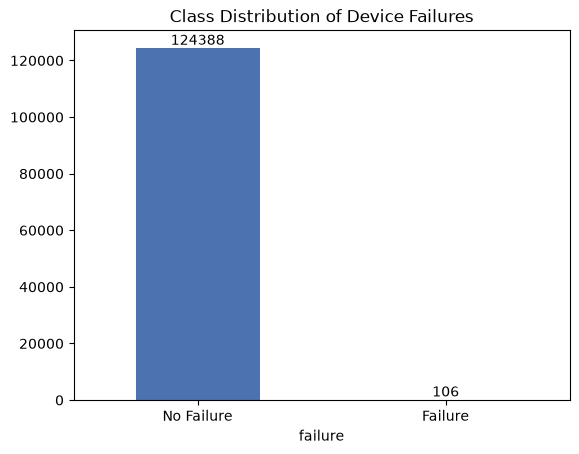

In [13]:
ax = df['failure'].value_counts().plot(kind='bar', color=['#4C72B0', '#DD5145'])
ax.bar_label(ax.containers[0])
plt.title('Class Distribution of Device Failures')
plt.xticks([0, 1], ['No Failure', 'Failure'], rotation=0)
plt.show()

In [14]:
(df['attribute7'] == df['attribute8']).all()

np.True_

In [15]:
df = df.drop('attribute8', axis=1)

Attribute7 and attribute8 are identical in every row, so attribute8 was dropped as a redundant feature.

In [16]:
df['device'].nunique()

1168

In [17]:
df[df['failure'] == 1]['device'].nunique()

106

106 of 1,168 devices (~9%) failed during the period, and each failed device failed exactly once.

In [18]:
records_per_device=df.groupby('device').size()
records_per_device.describe()

count   1168.00
mean     106.59
std      102.65
min        3.00
25%        6.00
50%       84.00
75%      224.00
max      304.00
dtype: float64

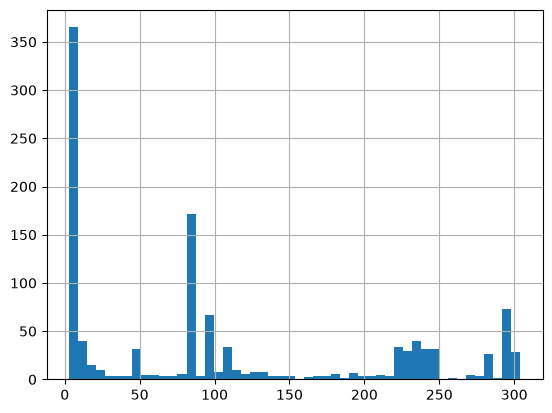

In [19]:
records_per_device.hist(bins=50)
plt.show()

In [20]:
last_day=df.groupby('device')['date'].max()
failure_day=df[df['failure'] == 1].set_index('device')['date']

In [21]:
(failure_day == last_day[failure_day.index]).mean()

np.float64(0.9528301886792453)

95% of failed devices stop reporting on the day of failure, so features such as the number of records per device would leak the target and were excluded.

In [22]:
df['device_type'] = df['device'].str[:3]
df.groupby('device_type').agg(devices=('device', 'nunique'),
                              failures=('failure', 'sum'))

,devices,failures
device_type,,
S1F,530,42
W1F,419,42
Z1F,219,22


Failure rates are similar across device types (S1F 7.9%, W1F 10.0%, Z1F 10.0%); device_type is kept as a categorical feature.

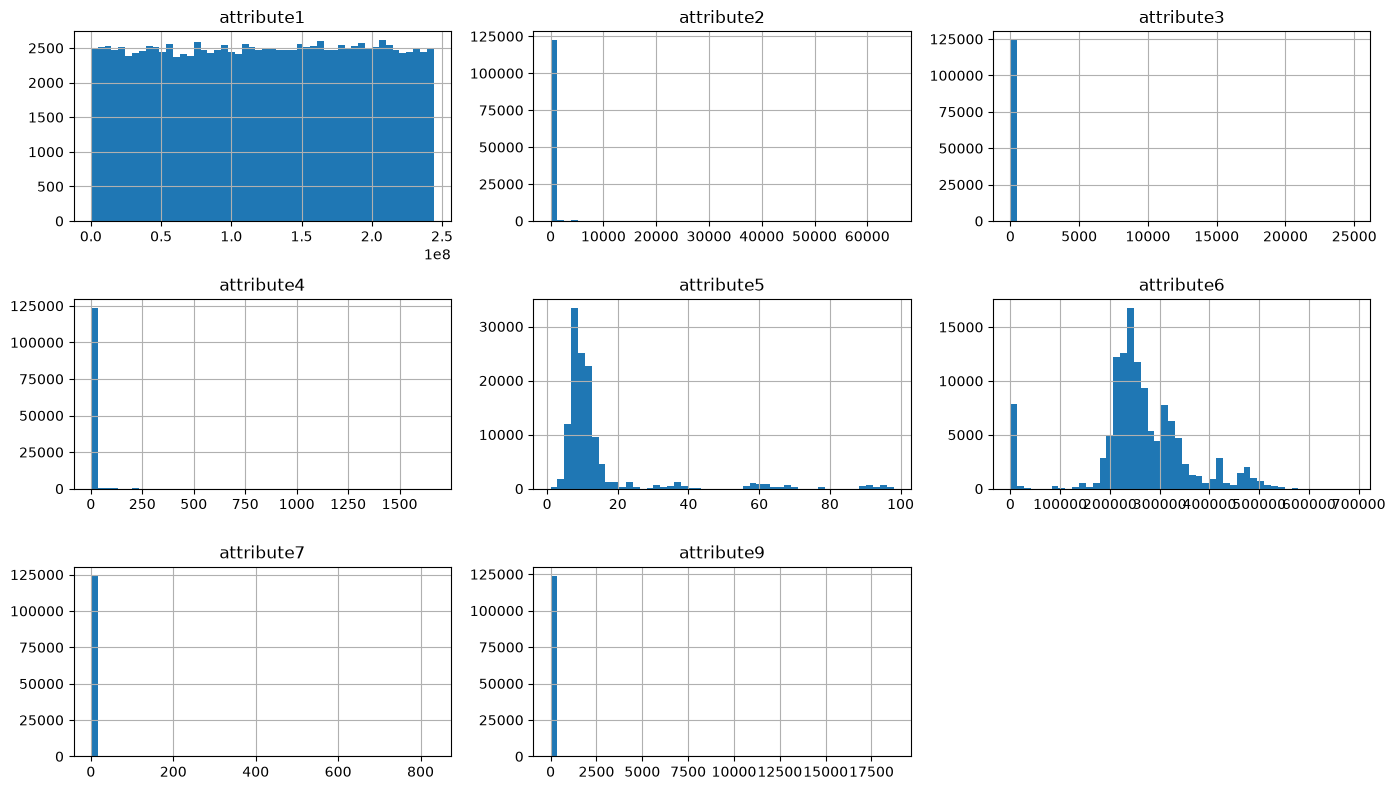

In [23]:
attrs = ['attribute1','attribute2','attribute3','attribute4',
         'attribute5','attribute6','attribute7','attribute9']
df[attrs].hist(bins=50, figsize=(14, 8))
plt.tight_layout()
plt.show()

In [24]:
df.groupby('failure')[attrs].agg(['mean', 'median']).T

failure                      0            1
attribute1 mean   122382671.81 127175526.92
           median 122785512.00 139117253.50
attribute2 mean         156.12      4109.43
           median         0.00         0.00
attribute3 mean           9.95         3.91
           median         0.00         0.00
attribute4 mean           1.70        54.63
           median         0.00         1.50
attribute5 mean          14.22        15.46
           median        10.00        10.00
attribute6 mean      260174.45    258303.48
           median    249794.00    267648.50
attribute7 mean           0.27        30.62
           median         0.00         0.00
attribute9 mean          12.44        23.08
           median         0.00         0.00

In [25]:
(df[attrs] > 0).groupby(df['failure']).mean().T

failure,0,1
attribute1,1.00,1.00
attribute2,0.05,0.45
attribute3,0.07,0.10
attribute4,0.07,0.58
attribute5,1.00,1.00
attribute6,1.00,1.00
attribute7,0.01,0.37
attribute9,0.22,0.28


attribute2, attribute4 and attribute7 are zero on most normal days but non-zero on 37–58% of failure days, making them the most promising predictors. attribute1, 5 and 6 are continuous and show little difference between classes.

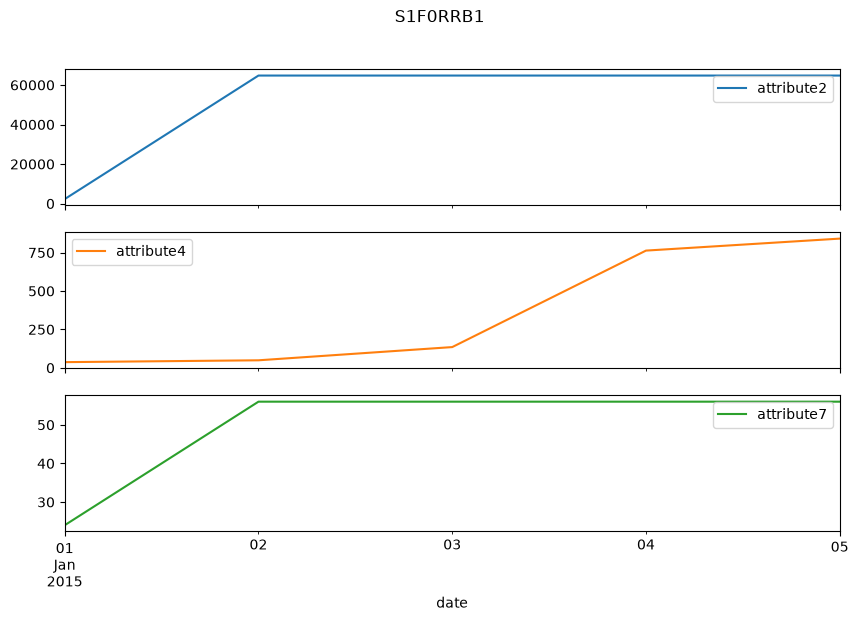

In [26]:
failed_devices = df[df['failure'] == 1]['device'].unique()
device = failed_devices[0]

d = df[df['device'] == device].set_index('date')
d[['attribute2', 'attribute4', 'attribute7']].tail(30).plot(subplots=True, figsize=(10, 6))
plt.suptitle(device)
plt.show()

In [27]:
df=df.sort_values(['device','date'])

for col in attrs:
    df[col + '_diff']=df.groupby('device')[col].diff().fillna(0)

In [28]:
diff_cols = [c + '_diff' for c in attrs]
df.groupby('failure')[diff_cols].apply(lambda x: x.abs().median()).T

failure,0,1
attribute1_diff,51592796.00,37956164.00
attribute2_diff,0.00,0.00
attribute3_diff,0.00,0.00
attribute4_diff,0.00,0.00
attribute5_diff,0.00,0.00
attribute6_diff,0.00,0.00
attribute7_diff,0.00,0.00
attribute9_diff,0.00,0.00


In [29]:
(df[diff_cols] != 0).groupby(df['failure']).mean().T

failure,0,1
attribute1_diff,0.99,0.99
attribute2_diff,0.01,0.20
attribute3_diff,0.00,0.00
attribute4_diff,0.00,0.22
attribute5_diff,0.00,0.03
attribute6_diff,0.41,0.46
attribute7_diff,0.00,0.12
attribute9_diff,0.00,0.00


### 2. Feature Engineering

In [30]:
key_attrs = ['attribute2', 'attribute4', 'attribute7']

for col in key_attrs:
    df[col + '_diff_7d'] = (df.groupby('device')[col + '_diff']
                              .transform(lambda s: s.rolling(7, min_periods=1).sum()))

In [31]:
cols_7d = [c + '_diff_7d' for c in key_attrs]
(df[cols_7d] != 0).groupby(df['failure']).mean().T #ek bilgi sağlıyor. 1 gündeki değişimden daha fazla etkili

failure,0,1
attribute2_diff_7d,0.02,0.34
attribute4_diff_7d,0.00,0.39
attribute7_diff_7d,0.00,0.25


In [32]:
for col in key_attrs:
    df[col + '_nonzero'] = (df[col] > 0).astype(int)

In [33]:
df['any_change_7d'] = (df[cols_7d] != 0).any(axis=1).astype(int)

In [34]:
pd.crosstab(df['any_change_7d'], df['failure'])

failure,0,1
any_change_7d,,
0,121339,44
1,3049,62


In [35]:
df = pd.get_dummies(df, columns=['device_type'], drop_first=True, dtype=int)

In [36]:
df.columns.tolist()

['date',
 'device',
 'failure',
 'attribute1',
 'attribute2',
 'attribute3',
 'attribute4',
 'attribute5',
 'attribute6',
 'attribute7',
 'attribute9',
 'attribute1_diff',
 'attribute2_diff',
 'attribute3_diff',
 'attribute4_diff',
 'attribute5_diff',
 'attribute6_diff',
 'attribute7_diff',
 'attribute9_diff',
 'attribute2_diff_7d',
 'attribute4_diff_7d',
 'attribute7_diff_7d',
 'attribute2_nonzero',
 'attribute4_nonzero',
 'attribute7_nonzero',
 'any_change_7d',
 'device_type_W1F',
 'device_type_Z1F']

### 3. Modelling

In [37]:
X = df.drop(columns=['date', 'device', 'failure', 'attribute1_diff',
                     'attribute3_diff', 'attribute6_diff', 'attribute9_diff'])
y = df['failure']
groups = df['device']

In [38]:
print(X.shape, y.value_counts().to_dict())

(124494, 21) {0: 124388, 1: 106}


In [39]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=23)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [40]:
print(X_train.shape, X_test.shape)
print(y_train.sum(), y_test.sum())
print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))

(99594, 21) (24900, 21)
85 21
set()


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf = RandomForestClassifier(random_state=23, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9991164658634538
[[24877     2]
 [   20     1]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24879
           1       0.33      0.05      0.08        21

    accuracy                           1.00     24900
   macro avg       0.67      0.52      0.54     24900
weighted avg       1.00      1.00      1.00     24900



Without handling imbalance, the model reaches 99.91% accuracy but catches only 1 of 21 failures (recall 5%). A model predicting ‘no failure’ for every row would score 99.92% accuracy, which shows that accuracy is meaningless here.

In [42]:
rf_w = RandomForestClassifier(class_weight='balanced', random_state=23, n_jobs=-1)
rf_w.fit(X_train, y_train)
y_pred_w = rf_w.predict(X_test)

print(confusion_matrix(y_test, y_pred_w))
print(classification_report(y_test, y_pred_w))

[[24872     7]
 [   20     1]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24879
           1       0.12      0.05      0.07        21

    accuracy                           1.00     24900
   macro avg       0.56      0.52      0.53     24900
weighted avg       1.00      1.00      1.00     24900



Adding `class_weight='balanced'` did not improve the results: the model still catches only 1 of 21 failures, and false alarms increased from 2 to 7. There are two likely reasons:

1. **Fully grown trees:** By default, each tree grows until it perfectly separates the training data, so the 85 failure cases are memorised and class weights have little effect.
2. **The 0.5 decision threshold:** `predict()` labels a row as a failure only if its predicted probability exceeds 0.5. Because failures are so rare, the model may assign failure probabilities well below 0.5, even when they are still higher than those of normal days.

To check the second explanation, we look at threshold-independent metrics. **ROC-AUC** and **PR-AUC** evaluate how well the model *ranks* failure days above normal days using the predicted probabilities, regardless of where the threshold is set. If these scores are high, the model has learned a useful signal and the problem lies in the threshold rather than the model itself.

In [43]:
from sklearn.metrics import roc_auc_score, average_precision_score

proba_w = rf_w.predict_proba(X_test)[:, 1]

print('ROC-AUC:', roc_auc_score(y_test, proba_w))
print('PR-AUC :', average_precision_score(y_test, proba_w))

ROC-AUC: 0.8521635190512556
PR-AUC : 0.06065051393705229


ROC-AUC is 0.85, meaning the model assigns a higher failure probability to a failure day than to a normal day 85% of the time. PR-AUC is 0.06, about 70 times higher than a random model would achieve (~0.0008, the failure rate). In other words, the model ranks failure days correctly, but their probabilities rarely exceed the default 0.5 threshold. Lowering the threshold should therefore improve recall.

In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

for t in [0.5, 0.3, 0.2, 0.1, 0.05, 0.02]:
    pred = (proba_w >= t).astype(int)
    print(f'eşik={t:<5} recall={recall_score(y_test, pred):.2f}  '
          f'precision={precision_score(y_test, pred, zero_division=0):.3f}  '
          f'f1={f1_score(y_test, pred):.3f}  alarm={pred.sum()}')

eşik=0.5   recall=0.05  precision=0.111  f1=0.067  alarm=9
eşik=0.3   recall=0.10  precision=0.054  f1=0.069  alarm=37
eşik=0.2   recall=0.10  precision=0.019  f1=0.032  alarm=105
eşik=0.1   recall=0.33  precision=0.014  f1=0.028  alarm=484
eşik=0.05  recall=0.48  precision=0.014  f1=0.028  alarm=691
eşik=0.02  recall=0.67  precision=0.011  f1=0.021  alarm=1318


Lowering the threshold increases recall at the cost of precision. At 0.05, the model catches 10 of 21 failures with 691 alarms; at 0.02, it catches 14 with 1,318 alarms. The best threshold is a business decision that depends on the cost of an inspection versus the cost of a missed failure. At this stage, the model performs roughly on par with the simple rule-based benchmark, which sets a clear target for the next steps.


In [45]:
from imblearn.over_sampling import SMOTE
from collections import Counter

X_res, y_res = SMOTE(random_state=23).fit_resample(X_train, y_train)

print('Önce :', Counter(y_train))
print('Sonra:', Counter(y_res))

Önce : Counter({0: 99509, 1: 85})
Sonra: Counter({0: 99509, 1: 99509})


In [46]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=23)),
    ('rf', RandomForestClassifier(random_state=23, n_jobs=-1))
])

pipe.fit(X_train, y_train)
proba_s = pipe.predict_proba(X_test)[:, 1]

print('ROC-AUC:', roc_auc_score(y_test, proba_s))
print('PR-AUC :', average_precision_score(y_test, proba_s))
print(confusion_matrix(y_test, (proba_s >= 0.5).astype(int)))

ROC-AUC: 0.8396084668844828
PR-AUC : 0.0309845532238828
[[24837    42]
 [   20     1]]


Effect of SMOTE (1:1)
Balancing the classes fully with SMOTE did not improve the model. Compared with `class_weight`, PR-AUC dropped from 0.061 to 0.031, false alarms rose from 7 to 42, and still only 1 of 21 failures was caught at the 0.5 threshold.

A likely reason is that SMOTE generated about 99,000 synthetic failure samples from only 85 real ones. With so few seed points, the synthetic samples do not reflect real failure behaviour well. In addition, SMOTE ignores the majority class when creating new samples, which adds noise where the two classes overlap, as they do here.

**SMOTE is not a guaranteed improvement.** Rather than applying it with default settings, we test it, measure its effect, and look for the setting that suits our data. Next, we try a milder oversampling ratio.

In [47]:
pipe_s10 = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(sampling_strategy=0.1, random_state=23)),
    ('rf', RandomForestClassifier(random_state=23, n_jobs=-1))
])

pipe_s10.fit(X_train, y_train)
proba_s10 = pipe_s10.predict_proba(X_test)[:, 1]

print('ROC-AUC:', roc_auc_score(y_test, proba_s10))
print('PR-AUC :', average_precision_score(y_test, proba_s10))

ROC-AUC: 0.8438355928407779
PR-AUC : 0.05870294601237862


In [48]:
#pip install lightgbm

In [49]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(class_weight='balanced', random_state=23, verbose=-1)
lgbm.fit(X_train, y_train)
proba_l = lgbm.predict_proba(X_test)[:, 1]

print('ROC-AUC:', roc_auc_score(y_test, proba_l))
print('PR-AUC :', average_precision_score(y_test, proba_l))

for t in [0.5, 0.1, 0.05, 0.02]:
    print(t, confusion_matrix(y_test, (proba_l >= t).astype(int)).ravel())

ROC-AUC: 0.8640122957016723
PR-AUC : 0.026051396720810225
0.5 [24777   102    18     3]
0.1 [24496   383    17     4]
0.05 [24179   700    12     9]
0.02 [23482  1397    11    10]


In [50]:
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression

models = {
    'LogReg': Pipeline([('scaler', StandardScaler()),
                        ('lr', LogisticRegression(class_weight='balanced', max_iter=1000))]),
    'RF_weighted': RandomForestClassifier(class_weight='balanced', random_state=23, n_jobs=-1),
    'RF_SMOTE': Pipeline([('scaler', StandardScaler()),
                          ('smote', SMOTE(sampling_strategy=0.1, random_state=23)),
                          ('rf', RandomForestClassifier(random_state=23, n_jobs=-1))]),
    'LGBM': LGBMClassifier(class_weight='balanced', random_state=23, verbose=-1),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=23)
groups_train = groups.iloc[train_idx]

oof = {}
for name, m in models.items():
    oof[name] = cross_val_predict(m, X_train, y_train, cv=cv, groups=groups_train,
                                  method='predict_proba')[:, 1]
    print(f'{name:12} ROC-AUC={roc_auc_score(y_train, oof[name]):.3f}  '
          f'PR-AUC={average_precision_score(y_train, oof[name]):.3f}')

LogReg       ROC-AUC=0.799  PR-AUC=0.024
RF_weighted  ROC-AUC=0.826  PR-AUC=0.037
RF_SMOTE     ROC-AUC=0.866  PR-AUC=0.025
LGBM         ROC-AUC=0.843  PR-AUC=0.035


Models were compared with 5-fold device-grouped cross-validation on the training set, so each score reflects all 85 training failures rather than the 21 in the test set. Random Forest with class weights achieved the highest PR-AUC (0.037) and was selected. SMOTE gave the best ROC-AUC but a lower PR-AUC, meaning more false alarms among its top-ranked predictions.

In [51]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_train, oof['RF_weighted'])

target_recall = 0.60
idx = np.where(recall[:-1] >= target_recall)[0][-1]
best_t = thresholds[idx]

print(f'Seçilen eşik: {best_t:.3f}')
print(f'CV recall: {recall[idx]:.2f}  precision: {precision[idx]:.3f}')

Seçilen eşik: 0.010
CV recall: 0.71  precision: 0.007


In [52]:
rf_final = RandomForestClassifier(n_estimators=500, class_weight='balanced',
                                  random_state=23, n_jobs=-1)

oof_rf = cross_val_predict(rf_final, X_train, y_train, cv=cv, groups=groups_train,
                           method='predict_proba')[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_rf)
idx = np.where(recall[:-1] >= 0.60)[0][-1]
best_t = thresholds[idx]

print(f'PR-AUC: {average_precision_score(y_train, oof_rf):.3f}')
print(f'Seçilen eşik: {best_t:.3f}  recall: {recall[idx]:.2f}  precision: {precision[idx]:.3f}')
print(f'Alarm oranı: {(oof_rf >= best_t).mean():.3f}')

PR-AUC: 0.042
Seçilen eşik: 0.030  recall: 0.60  precision: 0.014
Alarm oranı: 0.036


Increasing the number of trees to 500 makes the predicted probabilities finer-grained, so the threshold can be chosen more precisely. With a threshold of 0.03, cross-validated recall is 60% with 1.4% precision, raising alarms on 3.6% of device-days. PR-AUC improved from 0.037 to 0.042.

In [53]:
rf_final.fit(X_train, y_train)
proba_test = rf_final.predict_proba(X_test)[:, 1]
pred_model = (proba_test >= best_t).astype(int)
pred_rule = X_test['any_change_7d']

for name, pred in [('Model', pred_model), ('Kural', pred_rule)]:
    print(name)
    print(confusion_matrix(y_test, pred))
    print(f'recall={recall_score(y_test, pred):.2f}  '
          f'precision={precision_score(y_test, pred):.3f}  '
          f'alarm oranı={pred.mean():.3f}\n')

print('Test PR-AUC:', round(average_precision_score(y_test, proba_test), 3))

Model
[[23974   905]
 [    8    13]]
recall=0.62  precision=0.014  alarm oranı=0.037

Kural
[[24187   692]
 [    7    14]]
recall=0.67  precision=0.020  alarm oranı=0.028

Test PR-AUC: 0.065


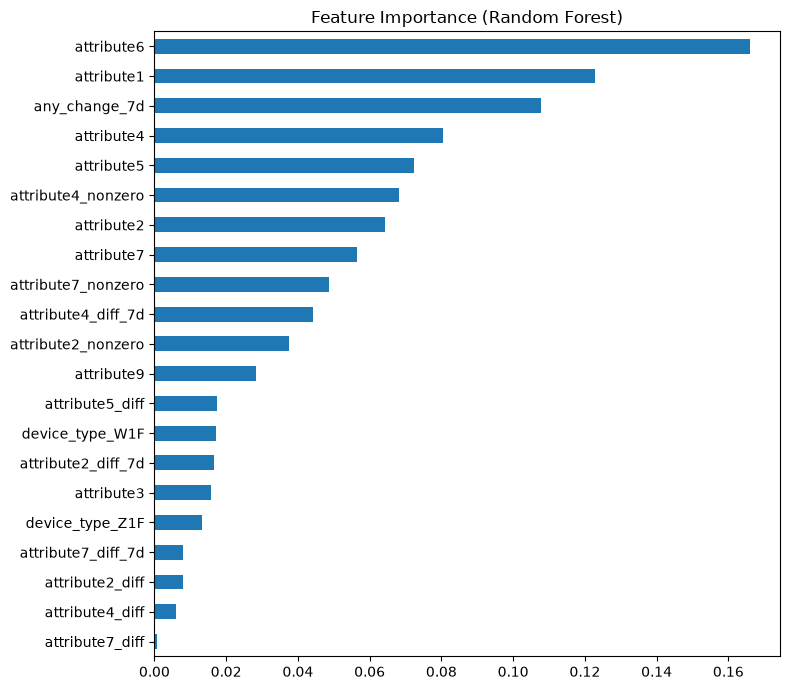

In [54]:
importance = pd.Series(rf_final.feature_importances_, index=X_train.columns)
importance.sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Feature Importance (Random Forest)')
plt.tight_layout()
plt.show()

###  4. Conclusion

- **Accuracy is misleading:** a model that never predicts a failure scores 99.9% accuracy but has no value. We evaluated models on recall, precision and PR-AUC instead.
- **Key insight:** a recent change (within 7 days) in attribute2, attribute4 or attribute7 is the strongest early-warning signal of failure.
- **Model vs. rule:** a Random Forest with class weights catches 62% of failures on unseen devices, while a simple rule built on the key insight performs equally well (67%) with fewer false alarms.
- **SMOTE:** full balancing hurt performance; a mild ratio helped but did not outperform class weighting.
- **Recommendation:** deploy the rule immediately, since it is simple, explainable and requires no infrastructure. Use the model's probabilities to prioritise inspections, starting with the highest-risk devices.
- **Next steps:** collect more failure cases, learn what the attributes measure, and estimate the actual costs of a missed failure and an unnecessary inspection to fine-tune the alarm threshold.